In [5]:
%pip install xgboost 

Note: you may need to restart the kernel to use updated packages.


In [6]:
import os, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [7]:
#Load data
CSV_PATH = "kolkata_weather_jan_june_2026.csv"

df = pd.read_csv(CSV_PATH)
print('Shape data:', df.shape)

df.head()

Shape data: (1827, 17)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [9]:
# Beberapa CSV cuaca (format Open-Meteo) punya 3 baris metadata di atas header
with open(CSV_PATH, encoding="utf-8", errors="ignore") as f:
    first_line = f.readline().lower()
skip = 3 if first_line.startswith("latitude") else 0

df = pd.read_csv(CSV_PATH, skiprows=skip)
# Rapikan nama kolom: buang satuan dalam kurung, mis. "temperature_2m_max (°C)" -> "temperature_2m_max"
df.columns = [c.split(" (")[0].strip() for c in df.columns]

print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
df.head()

Jumlah baris : 1827
Jumlah kolom : 17


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [8]:
print("=== Tipe data ===")
df.info()

=== Tipe data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   object 
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   object 
 12  sunset                       1827 non-null   object 
 13  

In [10]:
print("=== Ringkasan statistik ===")
df.describe().T

=== Ringkasan statistik ===


,count,mean,std,min,25%,50%,75%,max
weather_code,1827.0,34.143952,2.899722e+01,0.0000,3.0000,51.0000,63.0000,65.0000
temperature_2m_mean,1827.0,26.264860,4.050220e+00,15.0000,23.4000,27.4000,29.1000,35.2000
temperature_2m_max,1827.0,31.099234,3.924558e+00,19.6000,28.7000,31.3000,33.3000,43.9000
temperature_2m_min,1827.0,22.477066,4.847343e+00,10.2000,18.6000,24.6000,26.2000,30.6000
precipitation_sum,1827.0,5.429119,9.550693e+00,0.0000,0.0000,0.4000,7.3500,80.5000
rain_sum,1827.0,5.429119,9.550693e+00,0.0000,0.0000,0.4000,7.3500,80.5000
precipitation_hours,1827.0,4.952928,6.275264e+00,0.0000,0.0000,2.0000,9.0000,24.0000
wind_speed_10m_max,1827.0,13.782157,5.106847e+00,4.5000,10.0000,12.6000,16.6000,44.0000
wind_gusts_10m_max,1827.0,30.756596,9.081119e+00,11.5000,24.1000,29.5000,36.0000,83.9000
wind_direction_10m_dominant,1827.0,192.212917,1.001658e+02,0.0000,135.0000,188.0000,258.0000,360.0000


In [11]:
#Menentukan fitur (x) dan target (y)

def find_col(frame, keywords):
    """Cari nama kolom pertama yang mengandung salah satu keyword (urut prioritas)."""
    for k in keywords:
        for c in frame.columns:
            if k in c.lower():
                return c
    return None

DATE_COL   = find_col(df, ["date", "time", "tanggal"])
PRECIP_COL = find_col(df, ["precipitation_sum", "precip", "rain"])
RAIN_THRESHOLD = 1.0     # mm; hari dianggap "hujan" jika >= nilai ini

print("Kolom tanggal      :", DATE_COL)
print("Kolom curah hujan  :", PRECIP_COL)
assert DATE_COL and PRECIP_COL, "Kolom tanggal/curah hujan tidak terdeteksi. Isi DATE_COL dan PRECIP_COL secara manual."

Kolom tanggal      : time
Kolom curah hujan  : precipitation_sum


In [12]:
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df = df.dropna(subset=[DATE_COL]).sort_values(DATE_COL).reset_index(drop=True)

# Target = hujan besok. Hanya valid jika baris berikutnya benar-benar hari berikutnya.
next_precip = df[PRECIP_COL].shift(-1)
next_gap    = (df[DATE_COL].shift(-1) - df[DATE_COL]).dt.days
valid = next_precip.notna() & (next_gap == 1)

df["target"] = (next_precip >= RAIN_THRESHOLD).astype(int)
df["bulan"]  = df[DATE_COL].dt.month
df = df[valid].reset_index(drop=True)

print(f"Data valid: {len(df)} baris | periode {df[DATE_COL].min().date()} s/d {df[DATE_COL].max().date()}")
print("\nProporsi kelas target:")
print(df["target"].value_counts().rename({0: "Tidak Hujan (0)", 1: "Hujan (1)"}))
print(df["target"].value_counts(normalize=True).round(3))

Data valid: 1826 baris | periode 2021-06-30 s/d 2026-06-29

Proporsi kelas target:
target
Tidak Hujan (0)    984
Hujan (1)          842
Name: count, dtype: int64
target
0    0.539
1    0.461
Name: proportion, dtype: float64


In [13]:
# Eksplorasi Data (EDA)
# Cek missing value

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if missing.empty:
    print("Tidak ada missing value pada dataset.")
else:
    display(pd.DataFrame({"jumlah_kosong": missing, "persen": (missing / len(df) * 100).round(2)}))

Tidak ada missing value pada dataset.


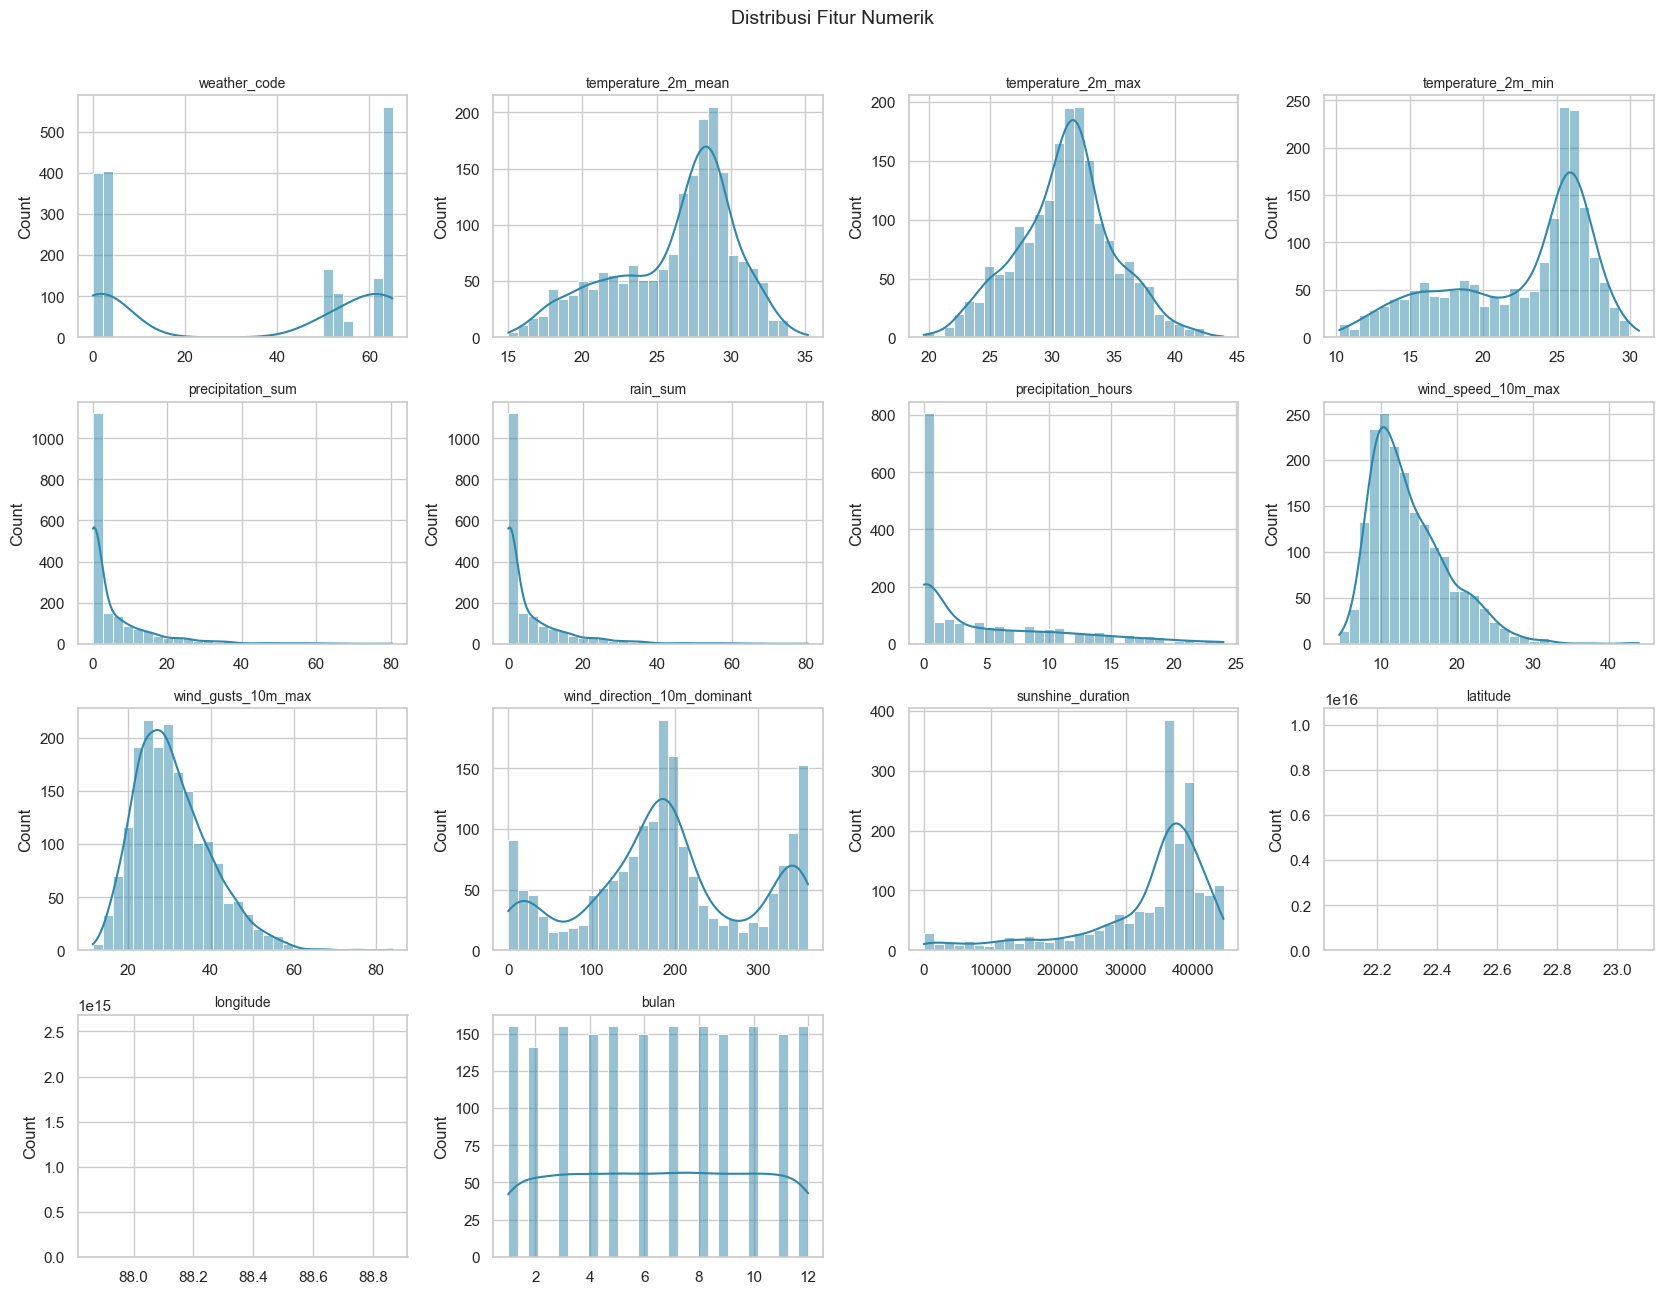

In [14]:
# Distribusi tiap fitur

num_cols = df.select_dtypes(include=np.number).columns.drop(["target"]).tolist()
n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.2 * n_rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=ax, color="#2E86AB")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
for ax in axes[len(num_cols):]:
    ax.axis("off")
plt.suptitle("Distribusi Fitur Numerik", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

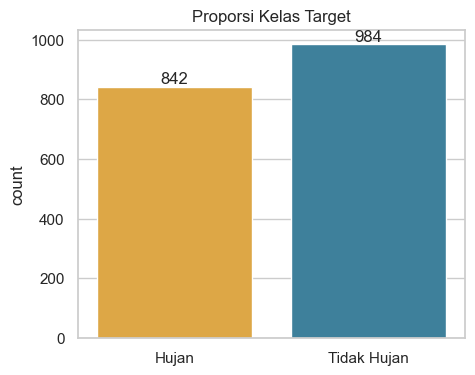

In [15]:
# Proporsi kelas target 

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df["target"].map({0: "Tidak Hujan", 1: "Hujan"}), ax=ax, palette=["#F6AE2D", "#2E86AB"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Proporsi Kelas Target")
ax.set_xlabel("")
plt.show()

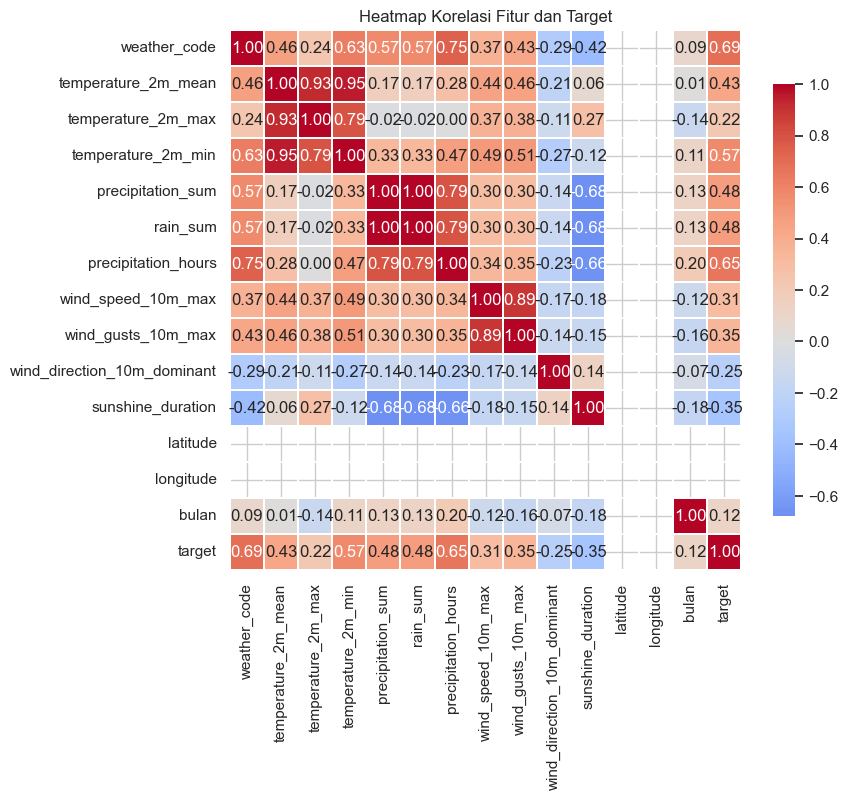

Korelasi fitur terhadap target (urut absolut):


weather_code                   0.689
precipitation_hours            0.654
temperature_2m_min             0.568
precipitation_sum              0.481
rain_sum                       0.481
temperature_2m_mean            0.431
sunshine_duration             -0.353
wind_gusts_10m_max             0.348
wind_speed_10m_max             0.306
wind_direction_10m_dominant   -0.249
temperature_2m_max             0.223
bulan                          0.119
latitude                         NaN
longitude                        NaN
Name: target, dtype: float64

In [16]:
# Korelasi antar fitur (heatmap)

corr = df[num_cols + ["target"]].corr()
size = max(8, 0.55 * len(corr))
plt.figure(figsize=(size, size * 0.85))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=len(corr) <= 15, fmt=".2f",
            linewidths=0.3, cbar_kws={"shrink": 0.8})
plt.title("Heatmap Korelasi Fitur dan Target")
plt.show()

print("Korelasi fitur terhadap target (urut absolut):")
corr["target"].drop("target").reindex(corr["target"].drop("target").abs().sort_values(ascending=False).index).round(3)

In [17]:
# Pra-pemrosesan Data
# Encoding variabel kategorikal

feature_df = df.drop(columns=[DATE_COL, "target"]).copy()
encoders = {}

for c in feature_df.select_dtypes(include="object").columns:
    parsed = pd.to_datetime(feature_df[c], errors="coerce")
    if parsed.notna().mean() > 0.9:                       # kolom waktu -> jam desimal
        feature_df[c] = parsed.dt.hour + parsed.dt.minute / 60
        print(f"[waktu]   {c} -> jam desimal")
    elif feature_df[c].nunique() <= 20:                   # kategorikal kecil -> LabelEncoder
        le = LabelEncoder()
        feature_df[c] = le.fit_transform(feature_df[c].astype(str))
        encoders[c] = le
        print(f"[encode]  {c} -> LabelEncoder ({len(le.classes_)} kelas)")
    else:
        feature_df = feature_df.drop(columns=[c])
        print(f"[dibuang] {c} (kategori terlalu banyak)")

# buang kolom tidak informatif
drop_cols = [c for c in feature_df.columns if feature_df[c].nunique(dropna=True) <= 1]
feature_df = feature_df.drop(columns=drop_cols)
print("Kolom konstan/kosong dibuang:", drop_cols)

X = feature_df.astype(float)
y = df["target"]
FEATURES = X.columns.tolist()
print(f"\nJumlah fitur: {len(FEATURES)}")
print(FEATURES)

[waktu]   sunrise -> jam desimal
[waktu]   sunset -> jam desimal
[encode]  city -> LabelEncoder (1 kelas)
Kolom konstan/kosong dibuang: ['city', 'latitude', 'longitude']

Jumlah fitur: 14
['weather_code', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunrise', 'sunset', 'sunshine_duration', 'bulan']


### 3.2 Standarisasi / Normalisasi
**Tidak diperlukan.** XGBoost adalah model berbasis pohon keputusan yang hanya melihat urutan nilai (threshold), sehingga tidak sensitif terhadap skala fitur. Standarisasi hanya akan berguna untuk model berbasis jarak/gradien seperti KNN, SVM, atau regresi logistik.

### 3.3 Pembagian Data Latih (80%) dan Data Uji (20%)
Karena ini **data deret waktu**, pembagian dilakukan **secara kronologis** (80% hari paling awal = latih, 20% hari terakhir = uji), bukan diacak. Jika diacak, hari yang bersebelahan (yang sangat mirip) bisa masuk ke data latih dan uji sekaligus, sehingga evaluasi menjadi terlalu optimis (*data leakage*).

In [18]:
# Pembagian data latih dan uji

split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train, y_test = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()

# Alternatif jika dosen meminta split acak berstrata:
# from sklearn.model_selection import train_test_split
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Data latih : {X_train.shape}  | {df[DATE_COL].iloc[0].date()} s/d {df[DATE_COL].iloc[split_idx-1].date()}")
print(f"Data uji   : {X_test.shape}  | {df[DATE_COL].iloc[split_idx].date()} s/d {df[DATE_COL].iloc[-1].date()}")
print("\nProporsi kelas data latih:\n", y_train.value_counts(normalize=True).round(3))
print("Proporsi kelas data uji:\n", y_test.value_counts(normalize=True).round(3))

Data latih : (1460, 14)  | 2021-06-30 s/d 2025-06-28
Data uji   : (366, 14)  | 2025-06-29 s/d 2026-06-29

Proporsi kelas data latih:
 target
0    0.542
1    0.458
Name: proportion, dtype: float64
Proporsi kelas data uji:
 target
0    0.525
1    0.475
Name: proportion, dtype: float64


### 3.4 Penanganan Missing Value & Pengecekan Data Leakage

In [19]:
# Median dihitung HANYA dari data latih, lalu dipakai untuk mengisi data latih dan uji
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test  = X_test.fillna(train_medians)

print("Missing value tersisa (latih/uji):", int(X_train.isnull().sum().sum()), "/", int(X_test.isnull().sum().sum()))

# Pengecekan leakage
assert df[DATE_COL].iloc[split_idx - 1] < df[DATE_COL].iloc[split_idx], "Data uji harus berada setelah data latih"
assert "target" not in X.columns, "Target tidak boleh ada di fitur"
print("Cek leakage OK: target digeser 1 hari, split kronologis, imputasi memakai statistik data latih saja.")

Missing value tersisa (latih/uji): 0 / 0
Cek leakage OK: target digeser 1 hari, split kronologis, imputasi memakai statistik data latih saja.


In [20]:
# Membangun model XGBoost

model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=RANDOM_STATE,
    eval_metric="logloss",
)
model.fit(X_train, y_train)

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
print("Model berhasil dilatih. Contoh 10 prediksi pertama:", y_pred[:10])

Model berhasil dilatih. Contoh 10 prediksi pertama: [1 1 1 1 1 1 1 1 1 1]


In [21]:
# Evaluasi model

metrics = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall":    recall_score(y_test, y_pred, zero_division=0),
    "F1-Score":  f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC":   roc_auc_score(y_test, y_proba),
}
metrics_df = pd.DataFrame(metrics, index=["Nilai"]).T.round(4)
display(metrics_df)

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=["Tidak Hujan", "Hujan"], zero_division=0))

,Nilai
Accuracy,0.8579
Precision,0.8177
Recall,0.9023
F1-Score,0.8579
ROC-AUC,0.9350



=== Classification Report ===
              precision    recall  f1-score   support

 Tidak Hujan       0.90      0.82      0.86       192
       Hujan       0.82      0.90      0.86       174

    accuracy                           0.86       366
   macro avg       0.86      0.86      0.86       366
weighted avg       0.86      0.86      0.86       366



In [22]:
print("=== Interpretasi Hasil ===")
print(f"- Akurasi {metrics['Accuracy']:.2%}: proporsi seluruh hari yang diklasifikasikan dengan benar.")
print(f"- Presisi {metrics['Precision']:.2%}: dari semua hari yang diprediksi hujan, sekian persen benar-benar hujan.")
print(f"- Recall {metrics['Recall']:.2%}: dari semua hari yang benar-benar hujan, sekian persen berhasil terdeteksi.")
print(f"- F1-Score {metrics['F1-Score']:.3f}: keseimbangan presisi dan recall.")
print(f"- ROC-AUC {metrics['ROC-AUC']:.3f}: makin mendekati 1 makin baik model membedakan hari hujan dan tidak hujan (0.5 = tebakan acak).")

=== Interpretasi Hasil ===
- Akurasi 85.79%: proporsi seluruh hari yang diklasifikasikan dengan benar.
- Presisi 81.77%: dari semua hari yang diprediksi hujan, sekian persen benar-benar hujan.
- Recall 90.23%: dari semua hari yang benar-benar hujan, sekian persen berhasil terdeteksi.
- F1-Score 0.858: keseimbangan presisi dan recall.
- ROC-AUC 0.935: makin mendekati 1 makin baik model membedakan hari hujan dan tidak hujan (0.5 = tebakan acak).


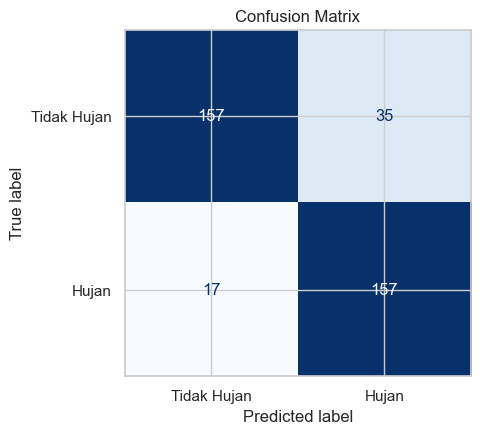

In [23]:
# Visualisasi Confusion Matrix

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Tidak Hujan", "Hujan"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix")
plt.show()

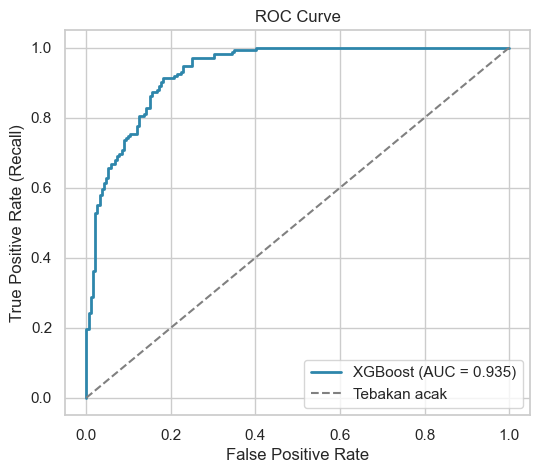

In [24]:
# Visualisasi ROC Curve

fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#2E86AB", lw=2, label=f"XGBoost (AUC = {metrics['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Tebakan acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

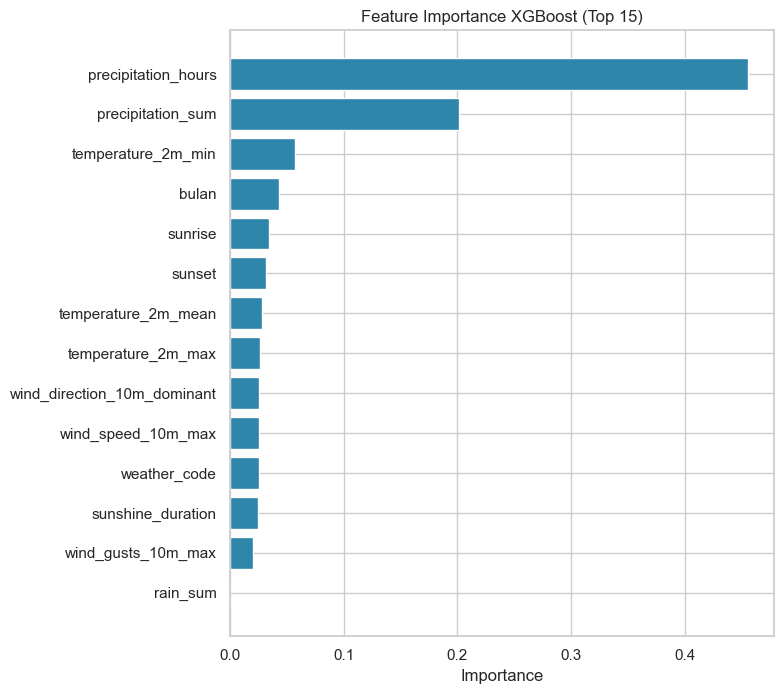

In [25]:
# Feature Importance

imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=True)
top = imp.tail(15)
plt.figure(figsize=(8, 0.4 * len(top) + 1.5))
plt.barh(top.index, top.values, color="#2E86AB")
plt.xlabel("Importance")
plt.title("Feature Importance XGBoost (Top 15)")
plt.tight_layout()
plt.show()

## Langkah 7 — Dashboard Streamlit
Sel berikut menyimpan model & data hasil pra-pemrosesan, lalu membuat file `app.py`.

In [26]:
# Dashboard streamlit
# Simpan model, data terproses, dan metadata untuk dashboard
model.save_model("model_xgb.json")

dash_df = X.copy()
dash_df.insert(0, "tanggal", df[DATE_COL].values)
dash_df["target"] = y.values
dash_df.to_csv("dashboard_data.csv", index=False)

meta = {
    "features": FEATURES,
    "split_ratio": 0.8,
    "rain_threshold": RAIN_THRESHOLD,
    "precip_col": PRECIP_COL,
}
with open("meta.json", "w") as f:
    json.dump(meta, f)

print("Tersimpan: model_xgb.json, dashboard_data.csv, meta.json")

Tersimpan: model_xgb.json, dashboard_data.csv, meta.json
